# Eksploracyjna analiza danych z Reddita

Notebook pobiera (jeśli brakuje lokalnych plików) posty z archiwum Reddit przez `01_fetch_reddit_data.py`, a następnie analizuje pliki CSV w katalogu `data/raw/reddit/`. Obejmuje kontrolę jakości, aktywność w czasie, wyniki postów, długość tekstu oraz porównanie subredditów.

Codebook (`codebook/codebook.yaml`) i instrument v1 (`src/digital_media_analysis/instruments/rules_v1.py`) są wspólne z notebookiem Wikipedii.

In [1]:
import subprocess
import sys
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

from digital_media_analysis.paths import PROJECT_ROOT, RAW_REDDIT_DIR, SCRIPTS_DIR

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)
sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = RAW_REDDIT_DIR
DATA_DIR.mkdir(parents=True, exist_ok=True)
files = sorted(DATA_DIR.glob("*.csv"))
if not files:
    print("Brak lokalnych danych Reddita. Uruchamiam pobieranie...")
    subprocess.run(
        [sys.executable, str(SCRIPTS_DIR / "01_fetch_reddit_data.py")],
        cwd=PROJECT_ROOT,
        check=True,
    )
    files = sorted(DATA_DIR.glob("*.csv"))
    if not files:
        raise FileNotFoundError(f"Pobieranie nie utworzyło plików CSV w {DATA_DIR}.")
[path.name for path in files]

['subreddit-gry.csv',
 'subreddit-lodz.csv',
 'subreddit-PolskaPolityka.csv',
 'subreddit-rower.csv',
 'subreddit-Szczecin.csv',
 'subreddit-warszawa.csv']

## Wczytanie i przygotowanie danych

Dane są łączone z wielu plików, a daty i zmienne liczbowe są jawnie konwertowane.

In [2]:
frames = []
for path in files:
    frame = pd.read_csv(path)
    frame["source_file"] = path.name
    frames.append(frame)

df = pd.concat(frames, ignore_index=True)
expected_columns = {
    "subreddit", "id", "title", "text", "created_utc", "created_at_utc",
    "url", "permalink", "score", "num_comments",
}
missing_columns = expected_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Brak wymaganych kolumn: {sorted(missing_columns)}")

df["created_at"] = pd.to_datetime(df["created_at_utc"], utc=True, errors="coerce")
for column in ["created_utc", "score", "num_comments"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")
df["title"] = df["title"].fillna("").astype(str)
df["text"] = df["text"].fillna("").astype(str)
df["title_chars"] = df["title"].str.len()
df["text_chars"] = df["text"].str.len()
df["total_chars"] = df["title_chars"] + df["text_chars"]
df["text_words"] = df["text"].str.findall(r"\b\w+\b").str.len()
df["year"] = df["created_at"].dt.year
df["month"] = df["created_at"].dt.strftime("%Y-%m")
df["weekday"] = df["created_at"].dt.day_name()
df["hour"] = df["created_at"].dt.hour
df.head()

,subreddit,id,title,text,created_utc,created_at_utc,url,permalink,score,num_comments,source_file,created_at,title_chars,text_chars,total_chars,text_words,year,month,weekday,hour
0,gry,a7nrq9,Bwin – otrzymaj bonus powitalny w wysokości 100% do 200 €,,1545235854,2018-12-19T16:10:54+00:00,http://dobramine.com/kasyno-online/bwin?utm_source=reddit_smm,/r/gry/comments/a7nrq9/bwin_otrzymaj_bonus_powitalny_w_wysokości_100_do/,1,0,subreddit-gry.csv,2018-12-19 16:10:54+00:00,57,0,57,0,2018,2018-12,Wednesday,16
1,gry,a7cjov,Wypełnij Swój koszyk z Mr Green,,1545150374,2018-12-18T16:26:14+00:00,http://dobramine.com/promocje/wypelnij-swoj-koszyk-z-mr-green?utm_source=twitter_smm,/r/gry/comments/a7cjov/wypełnij_swój_koszyk_z_mr_green/,1,0,subreddit-gry.csv,2018-12-18 16:26:14+00:00,31,0,31,0,2018,2018-12,Tuesday,16
2,gry,a6zt1p,Od piłki do hazardu online,,1545053331,2018-12-17T13:28:51+00:00,http://dobramine.com/promocje/od-pilki-do-hazardu-online?utm_source=reddit_smm,/r/gry/comments/a6zt1p/od_piłki_do_hazardu_online/,1,0,subreddit-gry.csv,2018-12-17 13:28:51+00:00,26,0,26,0,2018,2018-12,Monday,13
3,gry,a69js4,Stronka z grami za zadania,Można wyhaczyć darmowe gry: [https://www.bananki.pl/ps4/](https://www.bananki.pl/ps4/),1544826185,2018-12-14T22:23:05+00:00,https://www.reddit.com/r/gry/comments/a69js4/stronka_z_grami_za_zadania/,/r/gry/comments/a69js4/stronka_z_grami_za_zadania/,1,0,subreddit-gry.csv,2018-12-14 22:23:05+00:00,26,88,114,14,2018,2018-12,Friday,22
4,gry,a4umzh,SlotsFighter staje się częścią AskGamblers,,1544438806,2018-12-10T10:46:46+00:00,http://dobramine.com/blog/tresci-najwyzszej-klasy?utm_source=reddit_smm,/r/gry/comments/a4umzh/slotsfighter_staje_się_częścią_askgamblers/,2,0,subreddit-gry.csv,2018-12-10 10:46:46+00:00,42,0,42,0,2018,2018-12,Monday,10


## Rozmiar i jakość danych

In [3]:
quality = pd.Series({
    "liczba plików": len(files),
    "liczba postów": len(df),
    "liczba subredditów": df["subreddit"].nunique(),
    "unikalne identyfikatory": df["id"].nunique(),
    "najwcześniejszy post": df["created_at"].min(),
    "najpóźniejszy post": df["created_at"].max(),
    "brakujące daty": int(df["created_at"].isna().sum()),
    "brakujące tytuły": int((df["title"].str.strip() == "").sum()),
})
display(quality.to_frame("wartość"))
display(df.isna().sum().sort_values(ascending=False).to_frame("braki"))
display(df.describe(include="all").T)

,wartość
liczba plików,6
liczba postów,275
liczba subredditów,6
unikalne identyfikatory,275
najwcześniejszy post,2018-10-06 19:54:23+00:00
najpóźniejszy post,2026-10-13 10:40:52+00:00
brakujące daty,0
brakujące tytuły,0


,braki
url,1
subreddit,0
title,0
id,0
text,0
created_utc,0
created_at_utc,0
permalink,0
score,0
num_comments,0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
subreddit,275,6,lodz,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id,275,275,a7nrq9,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,275,257,Student w potrzebie,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
text,275,166,,87,NaN,NaN,NaN,NaN,NaN,NaN,NaN
created_utc,275.0,NaN,NaN,NaN,1751920024.549091,1538855663.0,1767654021.5,1790173603.0,1791623215.0,1791888052.0,77380357.002956
created_at_utc,275,275,2018-12-19T16:10:54+00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
url,274,269,https://forms.cloud.microsoft/Pages/ResponsePage.aspx?id=7xpEYw7al0O7fvnUcF6WO2KjEyJgYIlMrwmCfNS...,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
permalink,275,275,/r/gry/comments/a7nrq9/bwin_otrzymaj_bonus_powitalny_w_wysokości_100_do/,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
score,275.0,NaN,NaN,NaN,5.389091,0.0,1.0,1.0,3.0,191.0,18.192941
num_comments,275.0,NaN,NaN,NaN,3.327273,0.0,0.0,0.0,4.0,42.0,6.746869


## Porównanie subredditów

Oprócz średniej pokazujemy medianę i 90. percentyl, ponieważ wyniki postów są zwykle silnie skośne.

,subreddit,posts,median_score,mean_score,p90_score,median_comments,mean_comments,median_text_chars
0,PolskaPolityka,50,1.0,2.7,8.2,2.0,6.4,464.0
1,Szczecin,50,3.0,5.7,14.2,1.0,3.3,358.0
3,lodz,50,2.0,10.9,38.2,2.0,4.9,231.0
4,rower,50,1.0,1.0,1.0,0.0,0.1,0.0
5,warszawa,50,1.0,8.7,4.4,0.0,3.6,209.0
2,gry,25,1.0,1.2,2.0,0.0,0.0,0.0


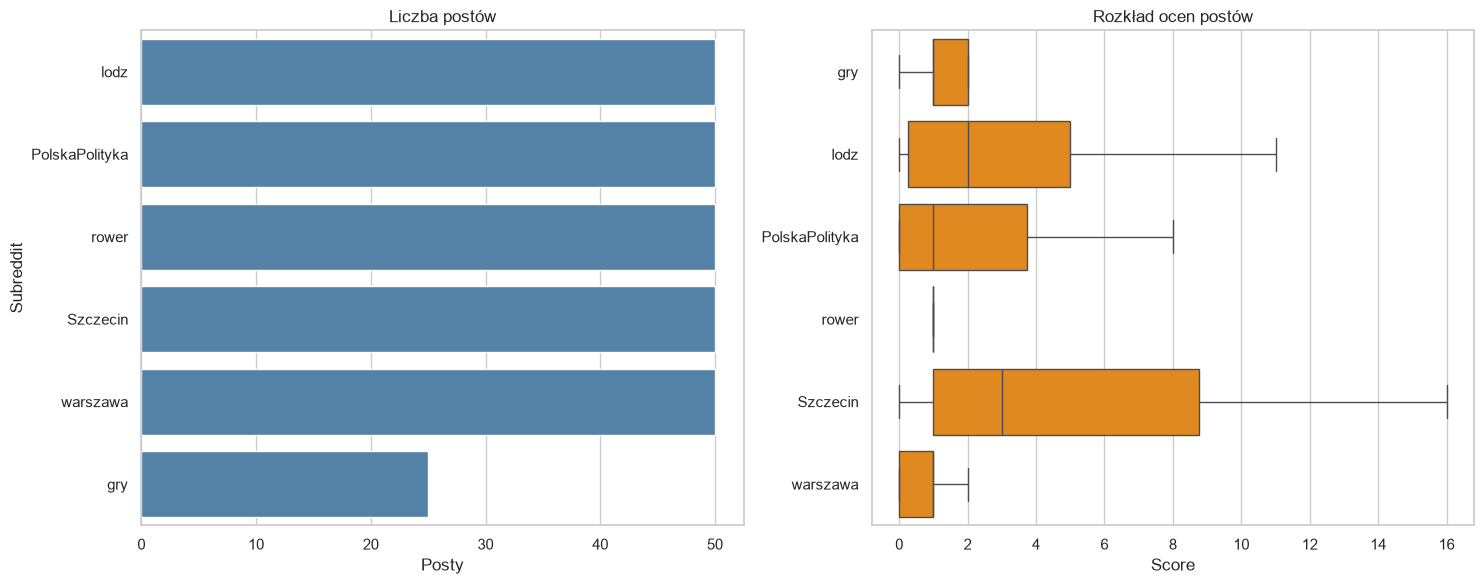

In [4]:
subreddit_summary = (
    df.groupby("subreddit", as_index=False)
      .agg(
          posts=("id", "size"),
          median_score=("score", "median"),
          mean_score=("score", "mean"),
          p90_score=("score", lambda values: values.quantile(.90)),
          median_comments=("num_comments", "median"),
          mean_comments=("num_comments", "mean"),
          median_text_chars=("text_chars", "median"),
      )
      .sort_values("posts", ascending=False)
)
display(subreddit_summary.round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.countplot(data=df, y="subreddit", order=df["subreddit"].value_counts().index, ax=axes[0], color="steelblue")
axes[0].set(title="Liczba postów", xlabel="Posty", ylabel="Subreddit")
sns.boxplot(data=df, y="subreddit", x="score", ax=axes[1], showfliers=False, color="darkorange")
axes[1].set(title="Rozkład ocen postów", xlabel="Score", ylabel="")
plt.tight_layout()

## Aktywność w czasie

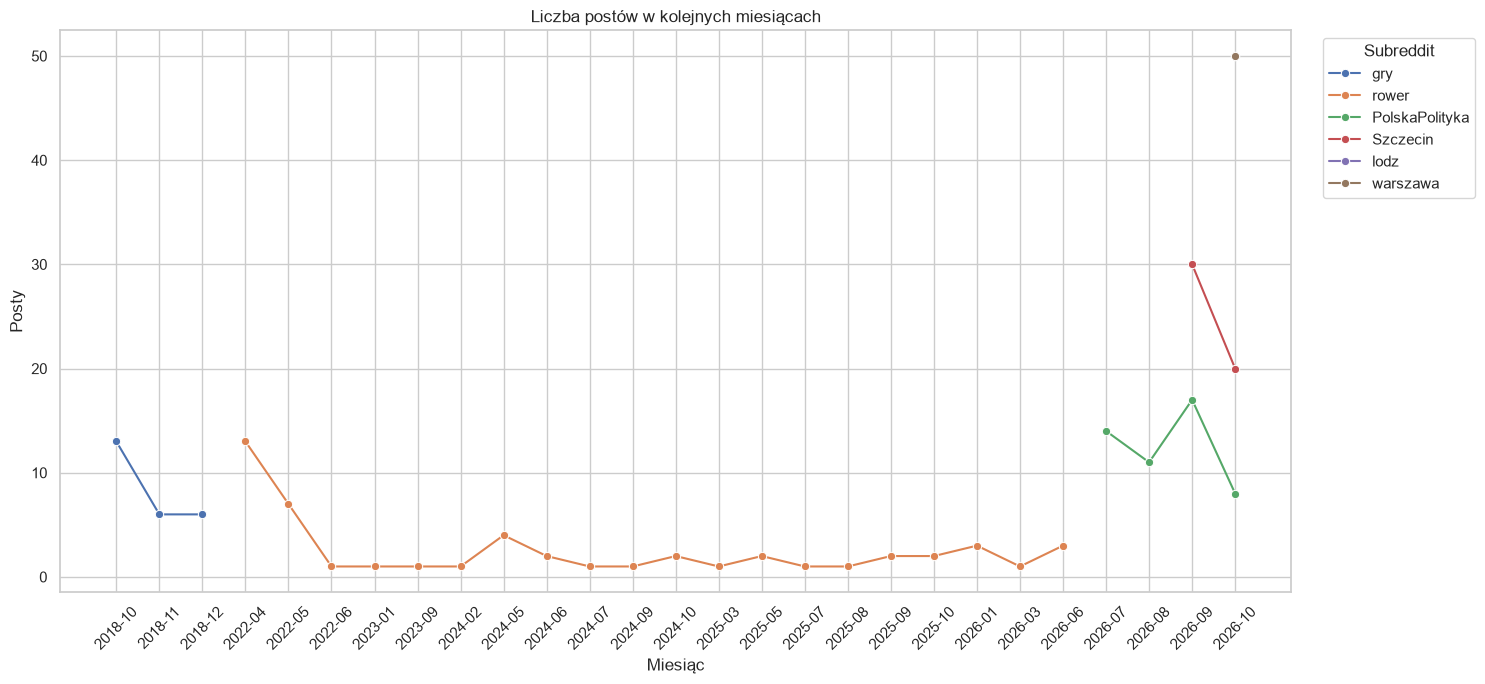

In [5]:
monthly_activity = (
    df.dropna(subset=["created_at"])
      .groupby(["month", "subreddit"], as_index=False)
      .size()
      .rename(columns={"size": "posts"})
)
plt.figure(figsize=(15, 7))
sns.lineplot(data=monthly_activity, x="month", y="posts", hue="subreddit", marker="o")
plt.title("Liczba postów w kolejnych miesiącach")
plt.xlabel("Miesiąc")
plt.ylabel("Posty")
plt.xticks(rotation=45)
plt.legend(title="Subreddit", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

## Dzień tygodnia i godzina publikacji

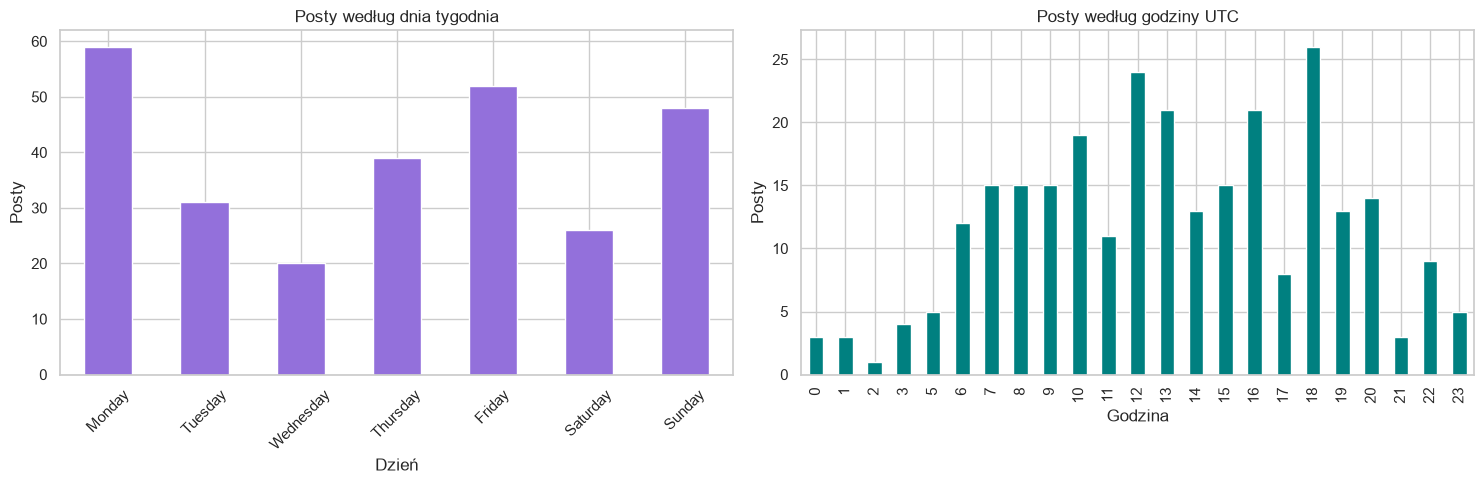

In [6]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_counts = df["weekday"].value_counts().reindex(weekday_order)
hour_counts = df["hour"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
weekday_counts.plot.bar(ax=axes[0], color="mediumpurple")
axes[0].set(title="Posty według dnia tygodnia", xlabel="Dzień", ylabel="Posty")
axes[0].tick_params(axis="x", rotation=45)
hour_counts.plot.bar(ax=axes[1], color="teal")
axes[1].set(title="Posty według godziny UTC", xlabel="Godzina", ylabel="Posty")
plt.tight_layout()

## Zależność między popularnością a dyskusją

,count,mean,std,min,25%,50%,75%,90%,99%,max
score,275.0,5.389091,18.192941,0.0,1.0,1.0,3.0,9.6,106.56,191.0
num_comments,275.0,3.327273,6.746869,0.0,0.0,0.0,4.0,10.0,31.82,42.0
title_chars,275.0,50.821818,28.261440,4.0,29.5,45.0,66.0,89.2,147.08,153.0
text_chars,275.0,638.418182,1925.235548,0.0,0.0,179.0,542.0,1271.6,10532.62,21271.0
text_words,275.0,91.894545,265.997791,0.0,0.0,28.0,80.0,211.2,1187.74,3024.0


,score,num_comments,title_chars,text_chars,text_words
score,1.00,0.35,-0.11,0.01,0.01
num_comments,0.35,1.00,-0.00,0.01,0.01
title_chars,-0.11,-0.00,1.00,0.14,0.14
text_chars,0.01,0.01,0.14,1.00,1.00
text_words,0.01,0.01,0.14,1.00,1.00


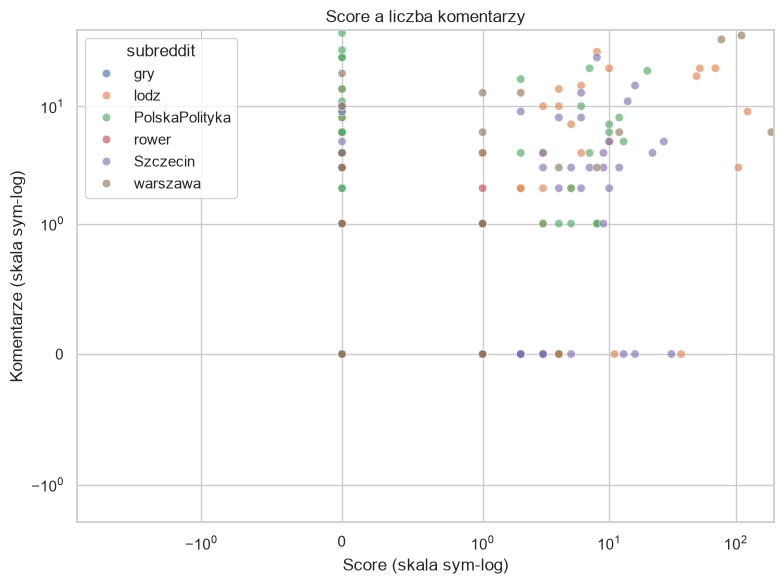

In [7]:
numeric_columns = ["score", "num_comments", "title_chars", "text_chars", "text_words"]
display(df[numeric_columns].describe(percentiles=[.25, .5, .75, .90, .99]).T)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="score", y="num_comments", hue="subreddit", alpha=.65)
plt.xscale("symlog", linthresh=1)
plt.yscale("symlog", linthresh=1)
plt.title("Score a liczba komentarzy")
plt.xlabel("Score (skala sym-log)")
plt.ylabel("Komentarze (skala sym-log)")
plt.tight_layout()

display(df[numeric_columns].corr().round(2))

## Najpopularniejsze posty

In [8]:
top_posts = (
    df.assign(title_preview=df["title"].str.replace(r"\s+", " ", regex=True).str.slice(0, 120))
      .nlargest(20, "score")
      [["subreddit", "title_preview", "score", "num_comments", "created_at", "permalink"]]
      .reset_index(drop=True)
)
display(top_posts)

,subreddit,title_preview,score,num_comments,created_at,permalink
0,warszawa,Prudential,191,6,2026-10-11 16:11:41+00:00,/r/warszawa/comments/1x3c4hk/prudential/
1,lodz,Ciri,124,9,2026-10-10 16:12:16+00:00,/r/lodz/comments/1x2j41u/ciri/
2,warszawa,Nowy Autobus Irizar ale w teoretycznym malowaniu taboru warszawskiego,111,40,2026-10-10 16:46:47+00:00,/r/warszawa/comments/1x2jxop/nowy_autobus_irizar_ale_w_teoretycznym_malowaniu/
3,lodz,Babcia - Jagoda z fabrycznego,105,3,2026-10-07 22:00:35+00:00,/r/lodz/comments/1x09p1h/babcia_jagoda_z_fabrycznego/
4,warszawa,Znowu policja lata i pilnuje kibiców żeby sobie kuku nie zrobili,77,37,2026-10-11 20:30:53+00:00,/r/warszawa/comments/1x3io94/znowu_policja_lata_i_pilnuje_kibiców_żeby_sobie/
5,lodz,Wiecie może co stało się dzisiaj w Manufakturze?,69,21,2026-10-05 17:22:12+00:00,/r/lodz/comments/1wyeh3x/wiecie_może_co_stało_się_dzisiaj_w_manufakturze/
6,lodz,Helikopterz nad łodzią,52,21,2026-10-11 10:09:50+00:00,/r/lodz/comments/1x34ibf/helikopterz_nad_łodzią/
7,lodz,Schemat linii komunikacji miejskiej,49,18,2026-10-09 14:48:34+00:00,/r/lodz/comments/1x1ncc5/schemat_linii_komunikacji_miejskiej/
8,lodz,Łódź Street Art | 2020 | Poland,37,0,2026-10-02 19:27:22+00:00,/r/lodz/comments/1ww2t5c/łódź_street_art_2020_poland/
9,Szczecin,Dzień gier planszowych,31,0,2026-10-06 09:41:56+00:00,/r/Szczecin/comments/1wyyd8w/dzień_gier_planszowych/


## Wnioski i ograniczenia

- `score` i `num_comments` opisują stan postu w chwili pobrania, a nie pełną dynamikę popularności.
- Zakres danych zależy od limitu `max_items` oraz dostępności postów przez API Reddita.
- Daty są analizowane w UTC, ponieważ tak zapisuje je scraper.
- Do analizy sentymentu, tematów lub języka potrzebne są dodatkowe metody przetwarzania tekstu.
- Wyniki między subredditami należy interpretować ostrożnie przy różnej liczbie obserwacji.

## Codebook v1.0

Jeden codebook dla Reddita i Wikipedii zastępuje dwa niezgodne schematy kategorii instrumentu v1. Źródłem prawdy jest `codebook/codebook.yaml`, a czytelną wersję dla annotatorów (`codebook/codebook.md`) generuje `make codebook`. Poniżej zmienne kodowane dla Reddita, kategorie `source_types` i reguły rozstrzygania.

In [9]:
from digital_media_analysis.codebook import load_codebook

codebook = load_codebook()
print(f"Codebook v{codebook.version} z {codebook.date}: {codebook.status}")
with pd.option_context("display.max_colwidth", 200):
    display(codebook.variables_frame("reddit"))
    display(codebook.categories_frame()[["kod", "nazwa", "definicja", "wykluczamy"]])
    display(codebook.rules_frame())

Codebook v1.0 z 2026-10-16: wersja robocza przed pilotażem annotacji


,zmienna,nazwa,typ,pytanie
0,cites_source,Powołanie się na źródło,binary,"Czy autor wskazuje, skąd pochodzi informacja lub na czym opiera twierdzenie?"
1,source_types,Typy źródeł,multilabel,Jakiego typu źródła przywołuje autor? Zaznacz wszystkie występujące.


,kod,nazwa,definicja,wykluczamy
0,media,Media informacyjne i publicystyczne,"Portale, gazety, telewizja, radio, agencje prasowe i magazyny publicystyczne.",media jako temat lub uczestnik zdarzenia („TVP zwolniła dziennikarza”); konto redakcji w serwisie społecznościowym bez linku do materiału redakcji (wtedy `platformy`)
1,oficjalne,Instytucje publiczne i oficjalne,"Organy władzy i administracji, urzędy, agencje rządowe i samorządowe, organizacje międzynarodowe (WHO, ECDC) oraz dokumenty urzędowe.","instytucja jako uczestnik zdarzenia („policja lata i pilnuje kibiców”, „Sejm uchwalił ustawę”); kontakt z urzędem opisany jako własne przeżycie (wtedy `osobiste`)"
2,nauka,"Nauka, badania i dane","Publikacje naukowe, uczelnie i instytuty, raporty badawcze, sondaże i zbiory danych ośrodków badawczych, biblioteki cyfrowe.","własne badanie autora, np. rekrutacja do ankiety (R8); osobista wizyta u lekarza (wtedy `osobiste`); ogólnik bez wskazania badania („badania pokazują”; wtedy `niesprecyzowane`)"
3,encyklopedie,"Encyklopedie, słowniki i bazy wiedzy","Encyklopedie (w tym artykuły Wikipedii), słowniki, poradnie językowe słowników i bazy wiedzy.","skróty zasad i narzędzi Wikipedii w opisach edycji (`[[WP:SK]]`, `[[WP:POP]]`, `[[Pomoc:…]]`; R9)"
4,platformy,Media społecznościowe i platformy treści użytkowników,"YouTube, Facebook, X/Twitter, TikTok, Instagram, Wykop, Reddit, fora i podobne serwisy.","zdjęcia i filmy autora hostowane przez platformę (i.redd.it, preview.redd.it, v.redd.it, imgur; R3); nazwa serwisu w innym znaczeniu, np. kod rabatowy „reddit100”"
5,komercyjne,Źródła komercyjne,"Sklepy, producenci, serwisy ogłoszeniowe i rezerwacyjne oraz strony firm użyte jako źródło informacji (cena, specyfikacja, opinie).","serwis jako miejsce poszukiwań lub przedmiot pytania („poza OLX i Otodom szukam innych stron”; R2); reklama, link afiliacyjny, spam, kod rabatowy (R3); sklep jako miejsce zdarzenia („sklepy zamyka..."
6,organizacje,"Organizacje pozarządowe, społeczne i polityczne","Fundacje, stowarzyszenia, NGO, związki zawodowe i partie polityczne jako wydawcy informacji.","organizacja jako temat lub uczestnik zdarzenia; polityk pełniący funkcję państwową, który mówi w imieniu urzędu (wtedy `oficjalne`)"
7,osobiste,Doświadczenie własne i relacje z drugiej ręki,"Autor opiera twierdzenie na własnym doświadczeniu albo na relacji konkretnej osoby z otoczenia, w tym specjalisty spotkanego osobiście.","opis sytuacji bez funkcji dowodu („mieszkam w centrum, można odebrać”); osoby jako uczestnicy, np. szukanie znajomych czy prezent dla znajomego; własna opinia („według mnie”, „moim zdaniem”; R8)"
8,niesprecyzowane,Ogólnikowe powołanie bez wskazania źródła,"Autor odwołuje się do źródła, którego nie da się zidentyfikować („badania pokazują”, „czytałem gdzieś”, „według ekspertów”, „wg źródła”).","sam znacznik „źródła/przypisy” lub „dodano przypis” w opisie edycji (to `edit_about_sources`; R10); słowo „link” lub „artykuł” w innym znaczeniu („podeślijcie link partnerkom”, „poprawiam link”); ..."
9,inne,Inne zidentyfikowane źródło,"Źródło dające się zidentyfikować (nazwa lub link), które nie pasuje do żadnej z powyższych kategorii, np. prywatny blog.","źródło pasujące do innej kategorii; `inne` stosujemy tylko w ostateczności; strona będąca przedmiotem rozmowy, np. aplikacja polecana w poście (R2)"


,reguła,treść
0,R1,"Etykietujemy całą jednostkę: post (tytuł, treść i link) albo opis zmiany. Przy `source_types` zaznacz każdą kategorię, która wystąpiła choć raz; liczba wystąpień nie ma znaczenia."
1,R2,"Powołanie wymaga funkcji źródła: tekst lub link musi wskazywać, skąd pochodzi informacja, albo podawać ją jako podstawę twierdzenia. Sama wzmianka o instytucji, osobie lub serwisie jako uczestniku..."
2,R3,"Nie są źródłem: własne zdjęcia i filmy hostowane przez platformę (i.redd.it, preview.redd.it, v.redd.it, imgur), formularze ankiet, reklamy, linki afiliacyjne, spam, kody rabatowe i linki do profi..."
3,R4,"Kategorię wyznacza wydawca lub kanał, z którego pochodzi informacja, a nie temat ani osoby opisane w materiale. Artykuł wp.pl o decyzji ministerstwa to `media`. Gdy autor wymienia też źródło pierw..."
4,R5,"Konkret wygrywa z ogólnikiem. `niesprecyzowane` zaznaczamy tylko wtedy, gdy jakieś odwołanie w jednostce pozostaje nierozpoznawalne. Jeśli ten sam fragment wskazuje konkretne źródło, kodujemy jego..."
5,R6,"Nie oceniamy wiarygodności. Tekst pseudonaukowy w repozytorium publikacji to nadal `nauka`, a artykuł z portalu o niskiej wiarygodności to nadal `media`."
6,R7,"Kategoria `inne` jest ostatecznością. Gdy domena jest nieznana, można sprawdzić, kto ją prowadzi, ale nie kodujemy treści strony docelowej."
7,R8,"Nie są powołaniem: własna opinia („według mnie”, „moim zdaniem”), prośba o źródło („macie jakieś dane?”) ani własne badanie autora (rekrutacja do ankiety)."
8,R9,"Wikipedia, elementy techniczne. Pomijamy automatyczny prefiks sekcji `/* … */`. Skróty zasad i narzędzi (`[[WP:…]]`, `[[Pomoc:…]]`), opisy redakcyjne („drobne redakcyjne”, „int.”, „kat.”), komunik..."
9,R10,"Wikipedia, praca nad przypisami. Deklaracja pracy nad źródłami (znacznik „źródła/przypisy”, „dodano przypis”, poprawa przypisów) daje `edit_about_sources = 1`. `cites_source = 1` dajemy tylko wted..."


## Instrument v1: odniesienia do źródeł w treści wpisów

Eksport Reddita użyty w tym notebooku zawiera pole `text` (treść wpisu), ale nie ma osobnego pola komentarzy. Ekstraktor analizuje więc `text`; jeżeli w danych pojawi się kolumna `comment`, `comment_text` lub `body`, zostanie ona wykorzystana automatycznie. Tytuł i pole `url` nie są analizowane.

Model jest hybrydowy i działa lokalnie: wykrywa adresy URL/domeny, nazwy serwisów oraz językowe sygnały powoływania się na źródło. Następnie przypisuje odniesienie do kategorii źródła i nadaje mu wynik pewności.

Kod ekstraktora przeniesiono bez zmian do `src/digital_media_analysis/instruments/rules_v1.py` i zamrożono jako punkt odniesienia dla walidacji. Daje te same wyniki co wersja, która wcześniej była wklejona w tę komórkę. Poprawki trafią do kolejnej wersji instrumentu, a nie do v1.

In [10]:
from digital_media_analysis.instruments import rules_v1

text_columns = [column for column in rules_v1.REDDIT_TEXT_COLUMNS if column in df.columns]
analysis_column = text_columns[0] if text_columns else "title"
references_df = rules_v1.extract_reddit_references(df, text_column=analysis_column)
if references_df.empty:
    print(f"Nie wykryto odniesień w kolumnie '{analysis_column}'.")
else:
    print(f"Analizowana kolumna: {analysis_column}; wykryte odniesienia: {len(references_df)}")
    display(references_df.head(20))

Analizowana kolumna: text; wykryte odniesienia: 197


,row_index,subreddit,score,num_comments,text_preview,reference,category,confidence
0,3,gry,1,0,Można wyhaczyć darmowe gry: [https://www.bananki.pl/ps4/](https://www.bananki.pl/ps4/),www.bananki.pl,link/domena,1.00
2,28,lodz,1,0,[Scent by You - Your Perfume Bar](https://preview.redd.it/s4qbiyon71vh1.jpg?width=4284&format=pj...,preview.redd.it,link/domena,1.00
3,30,lodz,1,0,"Zbieramy/szukamy znajomych 🥂 30M i 27K. Chcemy poznać nowych ludzi i zebrać grupkę, z którą możn...",znajomy,źródła osobiste i społecznościowe,0.85
4,32,lodz,3,4,Cześć wszystkim. Po latach męczarni i autosabotażu wybrałem się niedawno do psychiatry. Stwierdz...,lekarz,nauka i medycyna,0.85
5,33,lodz,1,4,"siema, mieszkam na wsi wsi. i jedyne co tu leci to po komunalny kabel internetowy. i musze przyz...",mieszkam,źródła osobiste i społecznościowe,0.85
6,34,lodz,4,0,To nie będzie zwykły koncert ani nostalgiczny powrót do kultowego filmu. „Soul Mission” to pełne...,pankoncert.pl,link/domena,1.00
7,43,lodz,124,9,"Cześć. Maluje jak mam czas i rozwijam hobby. Pomyślałem, że odezwę się tutaj bo może kogoś zaint...",mieszkam,źródła osobiste i społecznościowe,0.85
8,48,lodz,49,18,Jak w tytule. Interaktywny schemat dla tramwajów i autobusów. Działa na telefonie. Zapraszam do ...,gisboost.github.io,link/domena,1.00
9,51,lodz,0,8,"Zrobiłem aplikację z mapą lokali, które odwiedzali Książulo, MaciejJe, BigWojek i inni. Jak ktoś...",play.google.com,link/domena,1.00
11,52,lodz,3,1,"Cześć, piszę, bo nie mogę znaleźć konkretów w internecie. Jestem na ostatnim roku licencjatu z c...",koleżanka,źródła osobiste i społecznościowe,0.85


### Wyniki: na jakie źródła powołują się użytkownicy

,odniesienia,unikalne_źródła,średnia_pewność
category,,,
link/domena,97,63,1.00
media informacyjne,25,9,0.85
źródła osobiste i społecznościowe,22,7,0.85
nauka i medycyna,15,3,0.85
źródła oficjalne,12,6,0.85
źródła komercyjne,10,2,0.85
platformy i media społecznościowe,10,4,0.85
sygnał powołania,5,1,0.55
encyklopedie i bazy wiedzy,1,1,0.85


,,odniesienia,wpisy,średni_score
category,reference,,,
media informacyjne,wp.pl,10,10,1.30
źródła osobiste i społecznościowe,znajomy,10,10,6.50
link/domena,wiadomosci.wp.pl,10,10,1.30
źródła komercyjne,sklep,8,8,9.62
link/domena,forms.cloud.microsoft,6,6,1.17
źródła osobiste i społecznościowe,mieszkam,5,5,27.00
link/domena,www.money.pl,5,5,2.60
nauka i medycyna,lekarz,5,5,5.60
platformy i media społecznościowe,youtube,5,5,2.40


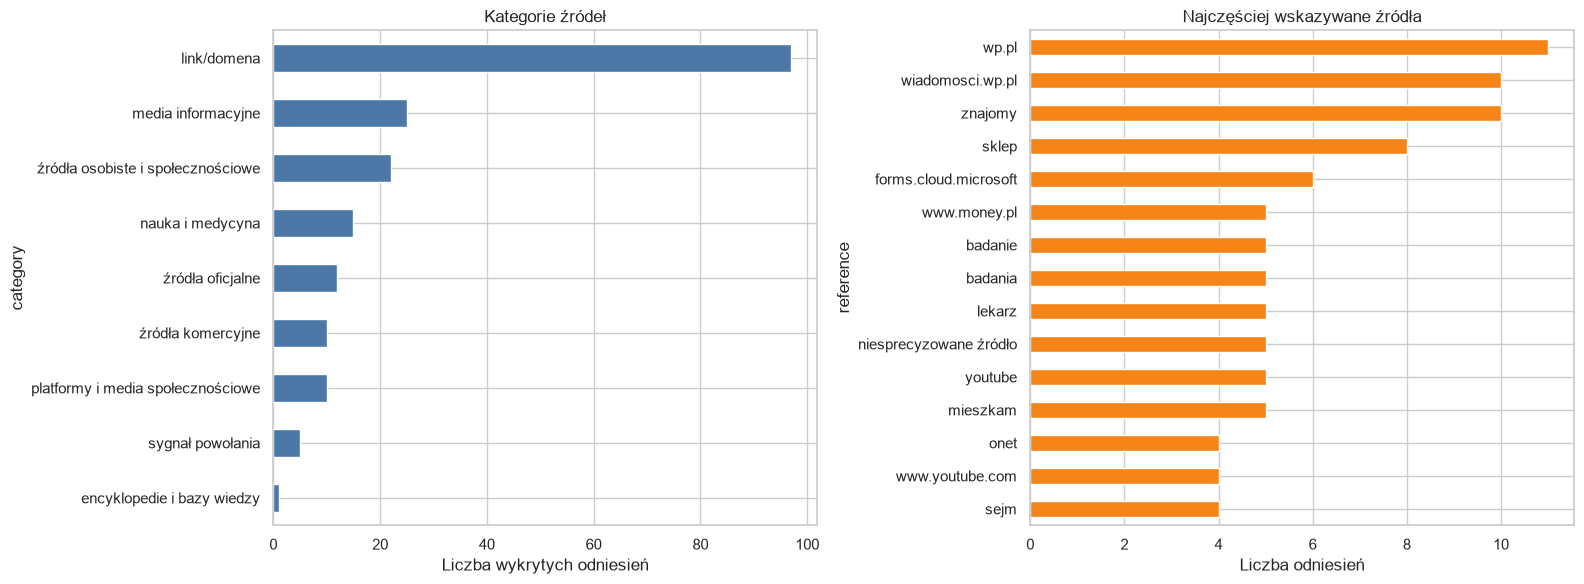

,category,reference,text_preview,subreddit
0,encyklopedie i bazy wiedzy,wikipedia,|Sondażownia|Dni badania|Próbka badawcza|[PiS](https://en.wikipedia.org/wiki/Law_and_Justice)|[K...,PolskaPolityka
1,link/domena,www.bananki.pl,Można wyhaczyć darmowe gry: [https://www.bananki.pl/ps4/](https://www.bananki.pl/ps4/),gry
2,media informacyjne,bbc,[https://krytykapolityczna.pl/swiat/maga-i-trump-rocznica-smierci-charlie-kirk/](https://krytyka...,PolskaPolityka
3,nauka i medycyna,lekarz,Cześć wszystkim. Po latach męczarni i autosabotażu wybrałem się niedawno do psychiatry. Stwierdz...,lodz
4,platformy i media społecznościowe,youtube,[https://krytykapolityczna.pl/swiat/maga-i-trump-rocznica-smierci-charlie-kirk/](https://krytyka...,PolskaPolityka
5,sygnał powołania,niesprecyzowane źródło,Cześć! Jakiś czas temu wrzuciłam tu ankietę do mojej pracy dyplomowej (badam różnice w jakości z...,lodz
6,źródła komercyjne,olx,Apart from olx and otodom is there any other web sites? I’m looking one that don’t force long te...,lodz
7,źródła oficjalne,gus,"Poszukuję osoby, która była dla mnie jak babcia. Była bezdomną (wyrzucona przez córkę), która du...",lodz
8,źródła osobiste i społecznościowe,znajomy,"Zbieramy/szukamy znajomych 🥂 30M i 27K. Chcemy poznać nowych ludzi i zebrać grupkę, z którą możn...",lodz


In [11]:
if not references_df.empty:
    category_summary = (
        references_df.groupby("category")
        .agg(odniesienia=("reference", "size"), unikalne_źródła=("reference", "nunique"), średnia_pewność=("confidence", "mean"))
        .sort_values("odniesienia", ascending=False)
    )
    source_summary = (
        references_df.groupby(["category", "reference"])
        .agg(odniesienia=("reference", "size"), wpisy=("row_index", "nunique"), średni_score=("score", "mean"))
        .sort_values("odniesienia", ascending=False)
    )
    display(category_summary.round(2))
    display(source_summary.head(30).round(2))

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    category_summary["odniesienia"].sort_values().plot.barh(ax=axes[0], color="#4c78a8")
    axes[0].set_title("Kategorie źródeł")
    axes[0].set_xlabel("Liczba wykrytych odniesień")
    top_sources = references_df["reference"].value_counts().head(15).sort_values()
    top_sources.plot.barh(ax=axes[1], color="#f58518")
    axes[1].set_title("Najczęściej wskazywane źródła")
    axes[1].set_xlabel("Liczba odniesień")
    plt.tight_layout()
    plt.show()

    examples = references_df.sort_values(["category", "confidence"], ascending=[True, False]).drop_duplicates("category")
    display(examples[["category", "reference", "text_preview", "subreddit"]].reset_index(drop=True))
else:
    print("Brak wyników do agregacji. Warto pobrać dane zawierające treść komentarzy lub wpisów.")

### Interpretacja i ograniczenia

Ekstraktor nie twierdzi, że każde wystąpienie nazwy jest formalnym cytowaniem źródła. Wynik `confidence` jest heurystyczną oceną dopasowania, a nie prawdopodobieństwem statystycznym. W obecnym eksporcie analizowana jest treść wpisów, ponieważ brak osobnych komentarzy. Do pełnej analizy komentarzy należy pobrać komentarze wraz z autorami i identyfikatorami, a następnie uruchomić te same komórki na kolumnie `comment`/`body`. Lista słów i domen może być rozszerzana o źródła specyficzne dla badanego tematu.

### Instrument v1 w kategoriach codebooka

Kategorie v1 są mapowane na kody codebooka, a wzmianki zwijane do etykiet na poziomie posta (`cites_source`, `source_types`). W tej postaci v1 będzie porównywany z gold standardem. Wzmianka `link/domena` liczy się jako powołanie, ale nie dostaje typu, bo v1 nie klasyfikuje domen.

Dwie rozbieżności z codebookiem widać bez annotacji. v1 liczy jako źródło każdy link, także zdjęcia i formularze ankiet (reguła R3). Nie widzi też linku w polu `url`, który według codebooka należy do jednostki analizy.

In [12]:
from digital_media_analysis.instruments.labels import to_document_labels

display(pd.DataFrame(
    {"kategoria v1": category, "kod codebooka": code or "(tylko cites_source)"}
    for category, code in rules_v1.REDDIT_CATEGORY_MAP.items()
))

v1_labels = to_document_labels(
    references_df,
    df.reset_index(names="row_index"),
    unit_columns=["row_index"],
    category_column="category",
    category_map=rules_v1.REDDIT_CATEGORY_MAP,
    non_citation=rules_v1.REDDIT_NON_CITATION,
)
detectable = set(rules_v1.REDDIT_CATEGORY_MAP.values())
coverage = (
    v1_labels["source_types"].str.split(";").explode()
    .loc[lambda codes: codes.ne("")]
    .value_counts()
    .reindex(codebook.category_codes, fill_value=0)
    .rename_axis("kod")
    .to_frame("posty wg v1")
)
coverage["v1 ma regułę"] = coverage.index.isin(detectable)
print(f"Posty z powołaniem wg v1: {v1_labels['cites_source'].sum()} / {len(v1_labels)}")
display(coverage)

non_source_hosts = ["i.redd.it", "preview.redd.it", "v.redd.it", "imgur.com", "forms.gle", "forms.cloud.microsoft", "docs.google.com"]
links_v1 = references_df[references_df["category"].eq("link/domena")]
print(f"Linki v1, które według R3 nie są źródłem (zdjęcia, ankiety): {links_v1['reference'].isin(non_source_hosts).sum()} z {len(links_v1)}")

url = df["url"].fillna("")
own_thread = pd.Series([f"/comments/{post_id}/" in link for post_id, link in zip(df["id"], url)], index=df.index)
url_outside_text = pd.Series([link not in text for link, text in zip(url, df["text"])], index=df.index)
unseen_links = url.ne("") & ~own_thread & url_outside_text
print(f"Posty z linkiem w polu `url`, którego v1 nie widzi: {unseen_links.sum()} z {len(df)}")
display(
    url[unseen_links].str.replace(r"^https?://", "", regex=True).str.split("/").str[0]
    .replace("", "(wątek Reddita)").value_counts().head(10).rename_axis("domena").to_frame("posty")
)

,kategoria v1,kod codebooka
0,link/domena,(tylko cites_source)
1,media informacyjne,media
2,źródła oficjalne,oficjalne
3,nauka i medycyna,nauka
4,platformy i media społecznościowe,platformy
5,encyklopedie i bazy wiedzy,encyklopedie
6,źródła komercyjne,komercyjne
7,źródła osobiste i społecznościowe,osobiste
8,sygnał powołania,niesprecyzowane


Posty z powołaniem wg v1: 99 / 275


,posty wg v1,v1 ma regułę
kod,,
media,21,True
oficjalne,10,True
nauka,13,True
encyklopedie,1,True
platformy,10,True
komercyjne,10,True
organizacje,0,False
osobiste,20,True
niesprecyzowane,5,True


Linki v1, które według R3 nie są źródłem (zdjęcia, ankiety): 13 z 97
Posty z linkiem w polu `url`, którego v1 nie widzi: 124 z 275


,posty
domena,
i.redd.it,27
dobramine.com,24
(wątek Reddita),12
www.reddit.com,10
youtube.com,7
forms.gle,4
youtu.be,4
v.redd.it,3
forms.cloud.microsoft,3


## Gold standard: próba do annotacji

Próbę losuje `make gold-sample` (`src/digital_media_analysis/gold.py`; ziarno, parametry i przydział lat w `annotations/sample_design.json`). Arkusze dla annotatorów eksportuje `make pilot-sheets`, a pełne dane wylosowanych jednostek zapisuje `make sample-csv` do `data_samples/` (w gicie). Manifest `annotations/sample_manifest.csv` zawiera tylko identyfikatory, rok, warstwy i wagi. Tekst trafia wyłącznie do arkuszy (poza gitem) i do plików CSV w `data_samples/`.

Schemat losowania:

1. Rama: jednostki z okresu badania danej platformy (`study_periods` w `config.yaml`). Każda platforma ma własny okres, bo służy innej hipotezie.
2. Pilotaż: mała próba z każdego roku do kalibracji codebooka. Nie wchodzi do metryk ani do ramy losowania próby głównej.
3. Próba główna: losowanie warstwowe z pozostałych jednostek. Każda platforma ma razem 500 jednostek (z pilotażem), rozdzielonych między lata tak równo, jak pozwalają dane. Dzięki temu oszacowania dla poszczególnych lat mają podobną precyzję. Rok mniejszy od równego udziału wchodzi w całości (`whole_years` w `sample_design.json`).
4. Podział wewnątrz każdej warstwy na `dev` (strojenie reguł i promptu) i `test` (tylko końcowy pomiar). Waga testowa N_h / n_h odtwarza liczebność warstwy w ramie.

**Reddit, lata 2005–2018.** Hipoteza: w latach 2005–2018 w przestrzeni online maleje zaufanie do konsensusu naukowego. Polskie subreddity powstały dopiero w 2008 r., a te z EDA mają posty od 2012 r., więc rama to angielskie subreddity o nauce (`reddit_frame` w `config.yaml`): r/reddit.com w 2005 r. (wtedy jedyne źródło, bo subreddity tematyczne jeszcze nie istniały), r/science od 2006 r., r/skeptic i r/conspiracy od 2008 r. Te subreddity są za duże, żeby pobrać je w całości, więc `make reddit-frame` pobiera wszystkie posty z jednego losowego dnia każdego miesiąca do `data/raw/reddit_frame/`. Rok, w którym wylosowane dni dają mniej niż 400 postów (2006), jest pobierany w całości. Posty usunięte przez moderację, filtry lub autora nie wchodzą do ramy. To inne dane niż najnowsze posty z polskich subredditów analizowane wyżej.

Warstwy to lata, każdy rok daje 35 lub 36 postów, w tym 2 do pilotażu. Waga posta uwzględnia też `day_weight`, czyli liczbę dni w miesiącu przypadającą na wylosowany dzień, więc odtwarza liczbę postów w całym roku, a nie tylko w wylosowanych dniach.

Skład subredditów zmienia się w czasie: w 2005 r. to ogólny r/reddit.com, w latach 2006–2007 tylko r/science, a od 2008 r. rośnie udział r/conspiracy. Różnice między latami mogą więc częściowo wynikać ze zmiany składu, a nie ze zmiany zaufania. Druga tabela pokazuje ten skład.

In [13]:
from digital_media_analysis import gold

try:
    manifest = gold.load_manifest()
except FileNotFoundError as error:
    print(error)
else:
    reddit_sample = manifest[manifest["platform"].eq("reddit")]
    display(gold.year_summary(manifest, "reddit"))
    display(pd.crosstab(reddit_sample["year"], reddit_sample["group"], margins=True, margins_name="razem"))
    display(gold.design_summary(manifest, "reddit").round(2))

,N (rama),pilot,dev,test
year,,,,
2005,685,2,11,22
2006,2473,2,11,23
2007,800,2,11,22
2008,1361,2,11,22
2009,1953,2,11,23
2010,1775,2,11,22
2011,2880,2,11,23
2012,4922,2,11,23
2013,5680,2,11,23


group,conspiracy,reddit.com,science,skeptic,razem
year,,,,,
2005,0,35,0,0,35
2006,0,0,36,0,36
2007,0,0,35,0,35
2008,2,0,33,0,35
2009,3,0,31,2,36
2010,4,0,29,2,35
2011,13,0,18,5,36
2012,14,0,19,3,36
2013,14,0,21,1,36


,N_h (rama),dev,test,waga test
stratum,,,,
2005,683,11,22,962.41
2006,2471,11,23,107.43
2007,798,11,22,1124.45
2008,1359,11,22,1853.18
2009,1951,11,23,2375.13
2010,1773,11,22,2498.32
2011,2878,11,23,3879.04
2012,4920,11,23,6417.39
2013,5678,11,23,7406.09


### Zgodność annotatorów w pilotażu

Po wypełnieniu arkuszy uruchom najpierw `make import-labels`. Ten krok sprawdza arkusze i zapisuje etykiety bez tekstu do `annotations/labels/pilot/`. Następnie `make agreement` zapisuje tabele i wykres do `annotations/agreement/`.

Poniżej te same miary dla Reddita:
- κ Cohena (dla dwóch osób) i α Krippendorffa: nominalna dla zmiennych 0/1, z odległością MASI dla całego zbioru typów źródeł;
- 95% przedziały bootstrap, z losowaniem jednostek ze zwracaniem;
- progi Krippendorffa: α ≥ 0,8 oznacza zgodność rzetelną, 0,667–0,8 pozwala tylko na wstępne wnioski.

Kategorii, które obie osoby razem zaznaczyły w mniej niż 5 jednostkach, nie oceniamy. W pilotażu dotyczy to większości typów źródeł, więc zgodność per kategoria rozstrzygnie dopiero próba główna. Niezgodności (z tekstem z danych lokalnych) to materiał na sesję uzgadniania i na slajd.

In [14]:
from digital_media_analysis import agreement, annotations, datasets
from digital_media_analysis.paths import RAW_REDDIT_FRAME_DIR

pilot_labels = annotations.load_labels("pilot")
pilot_labels = pilot_labels[pilot_labels["platform"].eq("reddit")]
if pilot_labels["annotator"].nunique() < 2:
    print("Brak etykiet pilotażu od dwóch osób. Po annotacji uruchom `make import-labels`.")
else:
    pilot_agreement = agreement.agreement_table(pilot_labels, codebook.category_codes)
    display(agreement.annotator_summary(pilot_labels).round(2))
    display(pilot_agreement.drop(columns="platform").round(2))
    agreement.plot_alpha(pilot_agreement)
    plt.show()
    # The sample is drawn from the year-by-year download, not from the newest posts analysed above.
    frame_posts = datasets.load_reddit_posts(RAW_REDDIT_FRAME_DIR)
    unit_texts = frame_posts.assign(unit_id=frame_posts["id"]).set_index("unit_id")[["title", "text"]]
    display(agreement.disagreements(pilot_labels).join(unit_texts, on="unit_id"))

Brak etykiet pilotażu od dwóch osób. Po annotacji uruchom `make import-labels`.
